In [1]:
from datetime import date
from understatapi import UnderstatClient
import pandas as pd

def get_season(season):
    with UnderstatClient() as understat:
        teams = understat.league(league="EPL").get_team_data(season=season)

    rows = []
    for team_id, team_info in teams.items():
        team_name = team_info['title']

        for match in team_info['history']:
            row = {'team':team_name, **match, 'season':season}
            rows.append(row)

    df = pd.DataFrame(rows)
    return df

    
df_now = get_season("2026")            # 2026 = season 2026/27
today = date.today().isoformat()       # e.g. "2026-10-12"

df_now.to_csv(f"epl_2026_as_of_{today}.csv", index=False)
print(df_now.shape) #118%20!=0 so probably 2 teams havent played yet(they are playing today 12/10/2026)

(120, 21)


In [2]:
games = df_now["team"].value_counts().sort_values()
print(games)

team
Aston Villa          6
Everton              6
Bournemouth          6
Sunderland           6
Crystal Palace       6
Chelsea              6
Tottenham            6
Arsenal              6
Newcastle United     6
Liverpool            6
Manchester City      6
Manchester United    6
Hull                 6
Brighton             6
Fulham               6
Brentford            6
Leeds                6
Nottingham Forest    6
Ipswich              6
Coventry             6
Name: count, dtype: int64


In [3]:
#Same logic with Session 1 but now we measure 'games' which calculates how many games each team has played
now = df_now.groupby("team").agg(
    games = ("pts","count"),
    pts = ("pts","sum"),
    xpts = ("xpts", "sum")
)

now["luck"] = now["pts"] - now["xpts"]
now["pts_per_game"] = now["pts"]/now["games"]
now["xpts_per_game"] = now["xpts"]/now["games"]

now = now.sort_values("luck", ascending = False)
print(now.round(2))

                   games  pts   xpts  luck  pts_per_game  xpts_per_game
team                                                                   
Manchester City        6   18  11.72  6.28          3.00           1.95
Arsenal                6   15  11.99  3.01          2.50           2.00
Hull                   6    9   6.05  2.95          1.50           1.01
Chelsea                6   10   7.21  2.79          1.67           1.20
Ipswich                6    9   6.68  2.32          1.50           1.11
Newcastle United       6    8   6.08  1.92          1.33           1.01
Brighton               6   13  11.19  1.81          2.17           1.87
Leeds                  6    9   7.86  1.14          1.50           1.31
Crystal Palace         6    7   5.99  1.01          1.17           1.00
Brentford              6   10   9.40  0.60          1.67           1.57
Coventry               6    6   5.50  0.50          1.00           0.92
Liverpool              6    9   8.56  0.44          1.50        

In [4]:
print(now.sort_values("xpts_per_game", ascending=False)[["pts_per_game", "xpts_per_game"]].round(2))

                   pts_per_game  xpts_per_game
team                                          
Arsenal                    2.50           2.00
Manchester City            3.00           1.95
Nottingham Forest          0.83           1.90
Brighton                   2.17           1.87
Everton                    1.67           1.64
Brentford                  1.67           1.57
Bournemouth                0.50           1.56
Manchester United          1.00           1.48
Liverpool                  1.50           1.43
Sunderland                 0.67           1.41
Leeds                      1.50           1.31
Tottenham                  0.50           1.28
Chelsea                    1.67           1.20
Fulham                     0.33           1.14
Ipswich                    1.50           1.11
Newcastle United           1.33           1.01
Hull                       1.50           1.01
Crystal Palace             1.17           1.00
Aston Villa                0.83           0.96
Coventry     

# **Note:** Nottingham Forest, Newcastle and Aston Villa stand out, for different reasons:

## **Nottingham Forest:**
By quality (xPts per game) it's 3rd, behind only Arsenal and City.
In the actual table, with just 5 points, it sits around 14th–15th. This is the biggest gap
in the league, making Forest the clearest candidate to climb.

## **Newcastle:**
The opposite case. By quality it's last (0.86 xPts per game), yet it already
has 8 points and sits mid-table. The most likely candidate to drop.

## **Aston Villa:**
Two things are happening at once:
- Last season's luck is gone: from +14 to −0.75 so far. Regression to the mean in action.
- Quality has dropped too: from 1.34 xPts per game last season (51 in 38 games) to 0.96 now,
  so Villa is genuinely playing worse, not just less lucky.

After only 6 games, part of these differences could still be noise.

In [5]:
now["games_left"] = 38 - now["games"]

now["proj_naive"] = now["pts"] + now["pts_per_game"] * now["games_left"]
now["proj_xpts"] = now["pts"] + now["xpts_per_game"] * now["games_left"]
now['diff'] = now["proj_xpts"] - now["proj_naive"]
now = now.sort_values("proj_xpts", ascending=False)
print(now[["pts", "proj_naive", "proj_xpts", "diff"]].round(1))



                   pts  proj_naive  proj_xpts  diff
team                                               
Manchester City     18       114.0       80.5 -33.5
Arsenal             15        95.0       78.9 -16.1
Brighton            13        82.3       72.7  -9.6
Nottingham Forest    5        31.7       65.9  34.3
Everton             10        63.3       62.6  -0.7
Brentford           10        63.3       60.1  -3.2
Liverpool            9        57.0       54.6  -2.4
Manchester United    6        38.0       53.5  15.5
Bournemouth          3        19.0       52.9  33.9
Leeds                9        57.0       50.9  -6.1
Sunderland           4        25.3       49.1  23.7
Chelsea             10        63.3       48.5 -14.9
Ipswich              9        57.0       44.6 -12.4
Tottenham            3        19.0       44.1  25.1
Hull                 9        57.0       41.3 -15.7
Newcastle United     8        50.7       40.4 -10.3
Crystal Palace       7        44.3       38.9  -5.4
Fulham      

### Projection: where will teams finish?

Two projections of final points, both keeping the points already earned:
- **Naive:** current points + remaining games × points per game so far ("same pace as now")
- **xPts-based:** current points + remaining games × xPts per game so far

Session 4 showed that xPts so far predicts remaining points better than the table at almost
every stage, so the xPts-based projection is the one we trust more. `diff` = xPts projection −
naive projection: positive means we expect the team to do better from here, negative worse.

**Expected to climb:**
- **Nottingham Forest** (+34): 14th–15th now, projected 4th. The biggest gap in the league.
- **Bournemouth, Fulham, Tottenham, Sunderland** (+24 to +34): all near the bottom now, but
  their xPts suggest they should get out of trouble.

**Expected to slow down:**
- **Manchester City and Arsenal** (−34, −16): their current pace isn't sustainable (the naive
  projection gives City 114 points), but they're still projected 1st and 2nd. Their *pace*
  drops, not their *position*.
- **Newcastle** (−10): 11th now with 8 points, projected 16th. One game (a loss to
  Coventry) moved this projection by 4 points and 2 places — a reminder of how noisy
  6-game samples are.
- **Hull, Chelsea, Ipswich** (−12 to −16): mid-table now, projected lower half.

**Limitations:**
- Only 6 games played. At this stage xPts predicts remaining points with r ≈ 0.67:
  better than the table, but far from certain. The projections are probably too extreme
  in both directions.
- Schedule isn't taken into account: a team that has already faced the top sides may have
  lower xPts than it deserves.
- Last season is ignored. Since quality persists year to year (r = 0.76), a stronger model
  would combine this season's xPts with last season's.

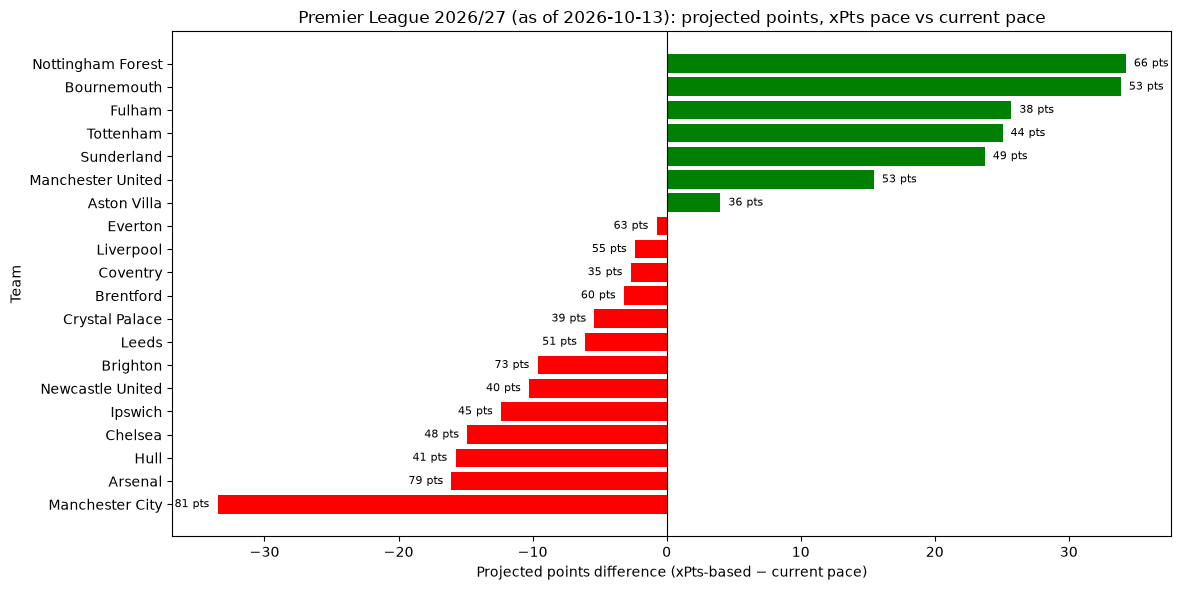

In [6]:
import matplotlib.pyplot as plt
plot_df = now.sort_values('diff')
colors = ["green" if x > 0 else "red" for x in plot_df['diff']]

fig, ax = plt.subplots(figsize=(12,6))


ax.barh(plot_df.index, plot_df['diff'], color = colors)
ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(f"Premier League 2026/27 (as of {today}): projected points, xPts pace vs current pace")
ax.set_xlabel("Projected points difference (xPts-based − current pace)")
ax.set_ylabel("Team")

for i, (team, row) in enumerate(plot_df.iterrows()):
    ax.text(row["diff"], i, f"  {row['proj_xpts']:.0f} pts  ",
            va="center", ha="left" if row["diff"] > 0 else "right", fontsize=8)

plt.tight_layout()
plt.savefig(f"projection_{today}.png", dpi=150)
plt.show()

In [7]:
print(now[["pts", "proj_naive", "proj_xpts", "diff"]].round(1))

                   pts  proj_naive  proj_xpts  diff
team                                               
Manchester City     18       114.0       80.5 -33.5
Arsenal             15        95.0       78.9 -16.1
Brighton            13        82.3       72.7  -9.6
Nottingham Forest    5        31.7       65.9  34.3
Everton             10        63.3       62.6  -0.7
Brentford           10        63.3       60.1  -3.2
Liverpool            9        57.0       54.6  -2.4
Manchester United    6        38.0       53.5  15.5
Bournemouth          3        19.0       52.9  33.9
Leeds                9        57.0       50.9  -6.1
Sunderland           4        25.3       49.1  23.7
Chelsea             10        63.3       48.5 -14.9
Ipswich              9        57.0       44.6 -12.4
Tottenham            3        19.0       44.1  25.1
Hull                 9        57.0       41.3 -15.7
Newcastle United     8        50.7       40.4 -10.3
Crystal Palace       7        44.3       38.9  -5.4
Fulham      